# Figure 3: weak CRE accessibility in methylation mutant cells

Groups CREs and TSSs by CpG content and WT accessibility, and compares Dnmt-TKO and Tet-TKO accessibility with WT.

Paper: Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **3a**: experimental scheme, no code (section: Fig. 3a, b)
- **3b**: correlation of accessibility profiles, no producer in this repo (section: Fig. 3a, b)
- **3c**: CREs per CpG bin, haCRE vs laCRE, ectoderm (section: CRE accessibility by CpG content)
- **3d**: Dnmt-TKO vs WT per CpG bin, ectoderm (section: CRE accessibility by CpG content)
- **3e**: Tet-TKO vs WT per CpG bin, ectoderm (section: CRE accessibility by CpG content)
- **3f**: binned scatters, CREs (section: Binned scatters)
- **3g**: binned scatters, TSSs (section: Binned scatters)
- **ED 6d**: as 3c-e, ExE mesoderm (section: CRE accessibility by CpG content)

Inputs: original analysis directory, via the repo's `data` link. Outputs: `out_path()` (`paths.R`), into `git_test/`.

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)

In [2]:
source(file.path(repo_dir, "scripts/lineage_peaks_func.r"))
source(file.path(repo_dir, "scripts/ATAC_preprocessing.r"))

- `mod` (`data/output/mod.RDS`): the ATAC model. Holds merged peaks (`mod$npeaks`), loci classified into modes (`mod$ehs`, e.g. `tss_hcg`, `icg_senh`, `icg_wenh`; see `scripts/ATAC_preprocessing.r`) and per-state coverage stats.
- `gen_peaks_lin()` (`scripts/lineage_peaks_func.r`) loads cached per-lineage peak counts from `data/output/lin_peaks.RDS` (present here). Otherwise `build_peak_mat()` builds them: trisomy-corrected, each genotype downsampled to a common coverage on ribosomal-protein TSSs.
- Each lineage matrix has columns WT, Dnmt-TKO, Dnmt-DKO, Tet-TKO.
- Ectoderm: `rnp_ds`. ExE mesoderm: `acp_ds` (amnion/chorion progenitors plus amnion/chorion).

In [3]:
mod = readRDS(in_path("./data/output/mod.RDS"))
mod <- gen_peaks_lin(mod)

## Fig. 3c-e and Extended Data Fig. 6d: CRE accessibility by CpG content

- **3c**: haCRE/laCRE counts and fractions per CpG bin, ectoderm
- **3d**: Dnmt-TKO vs WT per CpG bin, ectoderm
- **3e**: Tet-TKO vs WT per CpG bin, ectoderm
- **ED 6d**: same three plots, ExE mesoderm

Method (`plot_trends_cgbinned()`, `scripts/lineage_peaks_func.r`):
- CpG bins: max CpG density in a 500 bp window (0-1%, ..., 4-5%, >5%).
- Peaks within 1 kb of a TSS or > 1 Mb from one are removed.
- Accessibility: log2(1e-6 + peak's share of lineage total counts), per genotype.
- haCRE ("strong"): mean of WT, Dnmt-TKO and Tet-TKO ≥ -16.5; otherwise laCRE ("weak").
- Barplot: fraction of haCREs and laCREs per bin. Boxplots: Dnmt-TKO - WT and Tet-TKO - WT log2 differences per bin.

Caveats:
- `ylim(-1.5, 1.5)` drops values outside that range before boxplot statistics are computed.

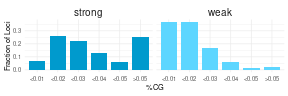

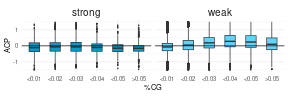

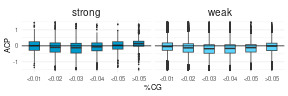

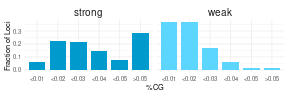

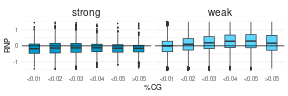

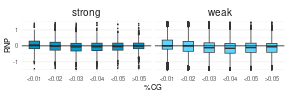

In [4]:
plot_trends_cgbinned(mod)

Writes, under `figs/Fig3/`:
- **3c**: `RNP_n_barplots.pdf`
- **3d**: `DNMT_RNP_boxplots.pdf`
- **3e**: `TET_RNP_boxplots.pdf`
- **ED 6d** (top, middle, bottom): `ACP_n_barplots.pdf`, `DNMT_ACP_boxplots.pdf`, `TET_ACP_boxplots.pdf`
- plotted tables: `data/ref/Fig3d_ACP_df.RDS`, `data/ref/Fig3d_RNP_df.RDS`

Caveat:
- `prep/E9.5_atac_peaks.ipynb` has a copy of this function that writes the same file names under `git_test/figs/Fig3` from E9.5 data; running it overwrites these panels.

haCRE test, ectoderm: paired two-sided Wilcoxon signed-rank, Dnmt-TKO vs WT, all CpG bins pooled.
- Not executed in the stored notebook.
- Reads the original `data/ref/Fig3d_RNP_df.RDS`, or the `git_test/` copy written above with `use_regenerated_inputs = TRUE` (`paths.R`).
- The p-values quoted in the text for 3d and 3e (4-5% or 3-4% bin vs lowest bin) are not computed here.

In [5]:
p2p_df <- readRDS(in_path("./data/ref/Fig3d_RNP_df.RDS")) %>% filter(mean_bin == "strong") 

pvals_df <- p2p_df %>%
  summarise(
    pval = wilcox.test(rnp.wt, rnp.dnmt_n, paired = TRUE)$p.value,
    .groups = "drop"
  )

pvals_df

## Fig. 3f, g: binned scatters of CRE and TSS accessibility

- **3f**: CRE accessibility, Dnmt-TKO vs WT (top) and Tet-TKO vs WT (bottom), per CpG bin; haCREs dark purple
- **3g**: same for TSSs; methylation-sensitive genes in blue

Method (`plot_scatters_cgbinned()`, `scripts/lineage_peaks_func.r`):
- Uses `mod$ehs` loci and their ectoderm counts from `data/output/lin_peaks_ehs.RDS`.
- Each locus's CpG content is first set to the max of `seq.CG_500_mean_new` over it; binned as above.
- Per bin (6): WT (x) vs Dnmt-TKO (top) and Tet-TKO (bottom), log2(1e-6 + share of total counts).
- Dashed lines: 2-fold change. Percentages: loci with log2 FC > 1 (top left) or < -1 (bottom right).
- **3f** modes: high-accessibility (`hcg_senh`, `icg_senh`, `lcg_senh`, dark purple) and low-accessibility (`hcg_wenh`, `icg_wenh`, `lcg_wenh`, light purple). Modes were assigned from mean WT ectoderm and ExE mesoderm accessibility, threshold -16.5.
- Low-CpG CREs between -18.5 and -16.5 (`lcg_menh`) are not plotted.
- **3g** modes: `tss_hcg`, `tss_icg`, `tss_lcg`, `tss_ctcf`, grey. TSSs of upregulated germline genes (Dahlet et al., 2020; `data/download/weber_genes.csv`) gaining > 2-fold are blue.

Caveat:
- The Tet-TKO row's y-axis title reads "DNMT TKO".

In [6]:
gvtrack.create("CG_max", "seq.CG_500_mean_new", "max")
ge = gextract("CG_max", intervals = mod$ehs, iterator = mod$ehs, colnames = "CG")
mod$ehs$CG = ge$CG

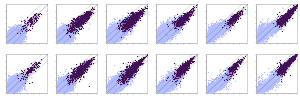

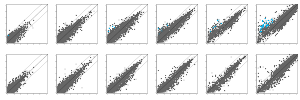

In [7]:
source(file.path(repo_dir, "scripts/lineage_peaks_func.r"))

plot_scatters_cgbinned(mod, suffix = "_CRE", weak_color = "#b3beff", strong_color = "#431259")

plot_scatters_cgbinned(mod, strong_modes = c("tss_hcg"), weak_modes = c("tss_icg", "tss_lcg", "tss_ctcf"), 
                       background_color = "grey40", weak_color = "grey40", strong_color = "grey40",
                       suffix = "_TSS", save_RDS = T)

Same scatters without percentages or bin titles: `figs/Fig3/binned_scatter_CG_rnp_CRE.png`, `binned_scatter_CG_rnp_TSS.png`. `save_RDS = T` has no effect (its code is commented out).

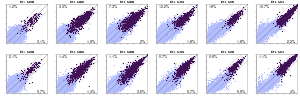

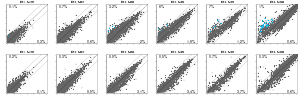

In [8]:
plot_scatters_cgbinned(mod, suffix = "_CRE_plus_percentages", weak_color = "#b3beff", strong_color = "#431259", add_labels = T)

plot_scatters_cgbinned(mod, strong_modes = c("tss_hcg"), weak_modes = c("tss_icg", "tss_lcg", "tss_ctcf"), 
                       background_color = "grey40", weak_color = "grey40", strong_color = "grey40",
                       suffix = "_TSS_plus_percentages", add_labels = T)

Published versions (six CpG bins as columns, Dnmt-TKO top, Tet-TKO bottom):
- **3f**: `figs/Fig3/binned_scatter_CG_rnp_CRE_plus_percentages.png`
- **3g**: `figs/Fig3/binned_scatter_CG_rnp_TSS_plus_percentages.png`

## Fig. 3a, b

- **3a**: schematic, scMultiome and EM-seq of chimeric embryos. No code.
- **3b**: accessibility profile correlation. No producer: `plot_lin_peaks()` was removed from `scripts/lineage_peaks_func.r`.